# Davis Southern Club Women: Who Moves With Whom, and Which Events Belong Together?

**Assignment · Network analysis of a two-mode (bipartite) social network**

DATA-620, Web Analytics, Fall 2026

Supervised by: **Professor Alain Ledon**


Submitted by: **Mehreen Ali Gillani**

---

## Abstract

This notebook analyses the classic Davis Club dataset: the recorded attendance of **18 Southern women at 14 social events**. The data form a *two-mode* network, with women on one side and events on the other, so every tie links a woman to an event. We work in both directions. We project the network onto the women (who shares events with whom) and onto the events (which events draw the same crowd), and we use community detection, centrality and similarity measures to describe the structure we find.

**Main findings.**
1. The women split into **two cohesive subgroups** (10 and 8 women), consistent with the two "cliques" reported in the original sociological study. The split is clearest when ties are weighted by the number of shared events.
2. The events split into an **"early" cluster (E1–E8)** and a **"late" cluster (E9–E14)**. Two large events, **E8 and E9**, are attended by women from *both* groups and act as the main meeting points.
3. A handful of women (e.g. **Theresa Anderson, Evelyn Jefferson, Nora Fayette, Sylvia Avondale**) are highly active. A small fringe (**Olivia Carleton, Flora Price, Dorothy Murchison**) attends only a couple of events.
4. Because the women's projection is almost completely connected (91% of all possible pairs share at least one event), **tie weights, not mere presence of a tie, carry the information**.

---

## 1. Introduction

**Background.** In the 1930s, Davis and his colleagues wanted to study social class and status among a group of women. To do this, they recorded which women showed up to which informal social events, parties, dinners, and so on. That record became a network: women on one side, events on the other, and a link whenever a woman attended an event..

**Why a bipartite network?** The ties are *attendance* ties: a woman attends an event, and women never attend other women directly. Two women are only linked indirectly, through shared events, and two events are only linked through shared guests.

**Questions we answer.**
1. **Women:** Do the women form distinct social groups? Who is central, who is peripheral, and who bridges the groups?
2. **Events:** Which events are similar, in the sense that they bring out the same guests? Which events are "meeting grounds" for different groups?

**Approach.**

| Step | Technique |
|---|---|
| Describe the raw data | Bipartite graph, biadjacency matrix, degree distributions |
| Women ↔ women | Weighted one-mode projection, community detection (greedy modularity) |
| Events ↔ events | Weighted projection, Jaccard similarity, community detection (greedy modularity) |
| Key actors | Degree/strength, betweenness, eigenvector centrality |
| Linking both views | Attendance of each women's community at each event |

**Data source.** https://networkx.org/documentation/stable/auto_examples/algorithms/plot_davis_club.html 

## 2. Setup and Data

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
from networkx.algorithms import bipartite
from networkx.algorithms.community import (
    greedy_modularity_communities, modularity)
    from itertools import combinations


sns.set_theme(style="white", context="notebook")
plt.rcParams["figure.dpi"] = 110

G = nx.davis_southern_women_graph()
women = G.graph["top"]       # 18 women
clubs = G.graph["bottom"]    # 14 events (called "clubs" in NetworkX)

print(f"Nodes: {G.number_of_nodes()}   Edges (attendances): {G.number_of_edges()}")
print(f"Women: {len(women)}   Events: {len(clubs)}")
print(f"Bipartite density: {bipartite.density(G, women):.3f}")

# Palette used consistently throughout: women = blue, events = orange,
# community 1 = red, community 2 = navy
C_WOMEN, C_EVENT = "#4C72B0", "#DD8452"
PALETTE = ["#E63946", "#1D3557"]

Nodes: 32   Edges (attendances): 89
Women: 18   Events: 14
Bipartite density: 0.353


**Reading the output.** The graph has 32 nodes and 89 attendance ties. Of the 18 × 14 = 252 possible woman–event pairs, about 35% are realised, so the network is moderately dense for a two-mode network. The average woman attends about 5 events, and the average event has about 6 attendees.

## 3. The Raw Bipartite Network

We first draw the network in its original two-mode form, with women on the left and events on the right. Node size is proportional to degree, so the busiest women and events stand out.

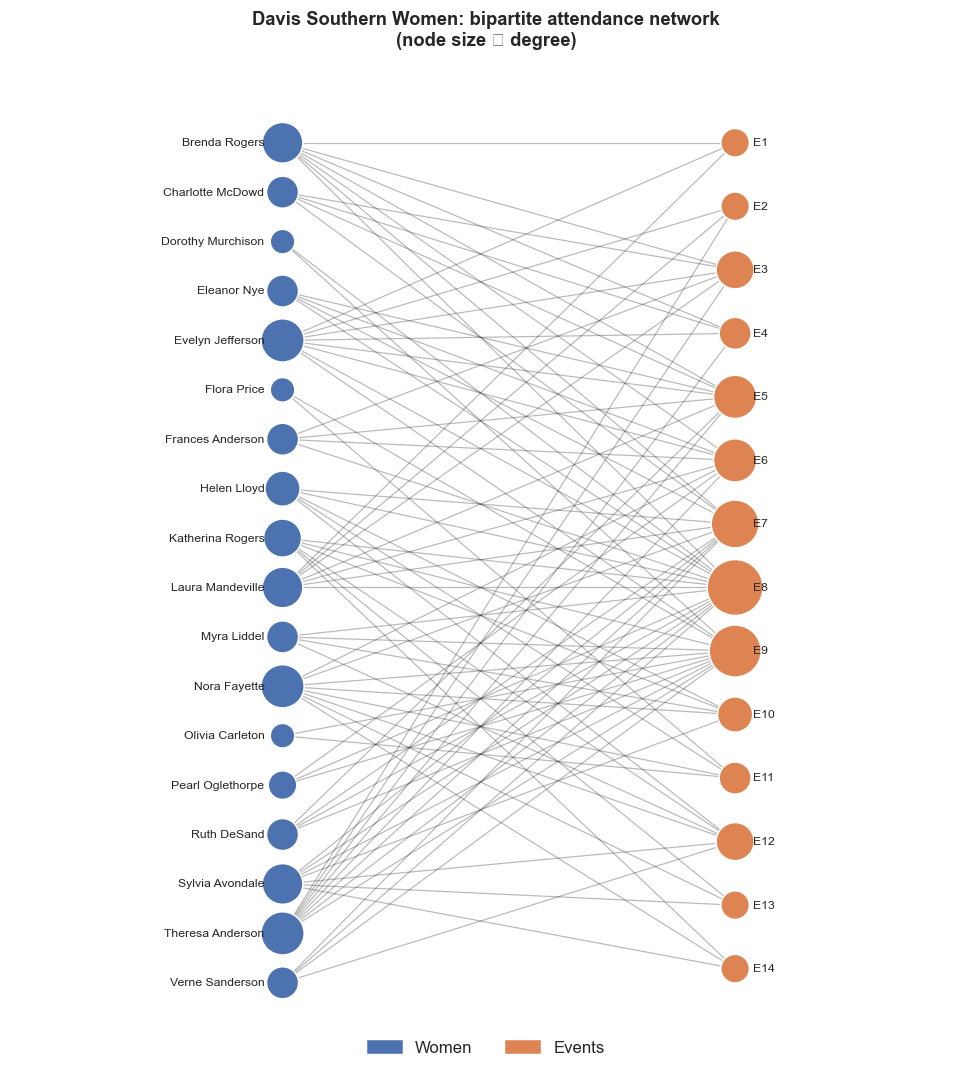

In [3]:
women_sorted = sorted(women)
clubs_sorted = sorted(clubs, key=lambda e: int(e[1:]))
pos_bi = {w: (0, -i) for i, w in enumerate(women_sorted)}
scale = len(women_sorted) / len(clubs_sorted)
pos_bi.update({e: (1, -i * scale) for i, e in enumerate(clubs_sorted)})

node_colors = [C_WOMEN if n in women else C_EVENT for n in G.nodes()]
node_sizes = [90 * G.degree(n) + 80 for n in G.nodes()]

fig, ax = plt.subplots(figsize=(9, 10))
nx.draw_networkx_edges(G, pos_bi, alpha=0.3, width=0.8, ax=ax)
nx.draw_networkx_nodes(G, pos_bi, node_size=node_sizes, node_color=node_colors,
                       edgecolors="white", linewidths=1, ax=ax)
for n, (x, y) in pos_bi.items():
    ax.text(x - 0.04 if n in women else x + 0.04, y, n, fontsize=8,
            ha="right" if n in women else "left", va="center")
ax.legend(handles=[mpatches.Patch(color=C_WOMEN, label="Women"),
                   mpatches.Patch(color=C_EVENT, label="Events")],
          loc="lower center", ncol=2, frameon=False)
ax.set_title("Davis Southern Women: bipartite attendance network\n(node size ∝ degree)", weight="bold")
ax.set_xlim(-0.6, 1.5); ax.axis("off")
plt.tight_layout(); plt.show()

**Interpretation.**
- Because every edge crosses between the two columns, the figure shows *who attended what*. It is hard to read group structure directly, since the order is only alphabetical and many edges cross.
- Even so, size differences are visible. **E8, E9 and E7** are the biggest event nodes and attract guests from across the list, while **E1, E2, E13 and E14** have only three guests each.
- Among the women, **Evelyn Jefferson, Theresa Anderson and Nora Fayette** (8 events each) are the largest nodes, whereas **Olivia Carleton, Flora Price and Dorothy Murchison** (2 events each) are small.
- A random ordering hides the structure, so the next section reorders the same data as a matrix to reveal it.

## 4. Attendance Matrix (Biadjacency Matrix)

In [4]:
A = bipartite.biadjacency_matrix(G, women, clubs)
print("Biadjacency matrix shape (women x events):", A.shape)
A_df = pd.DataFrame(A.toarray(), index=women, columns=clubs)
A_df

Biadjacency matrix shape (women x events): (18, 14)


,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,E11,E12,E13,E14
Evelyn Jefferson,1,1,1,1,1,1,0,1,1,0,0,0,0,0
Laura Mandeville,1,1,1,0,1,1,1,1,0,0,0,0,0,0
Theresa Anderson,0,1,1,1,1,1,1,1,1,0,0,0,0,0
Brenda Rogers,1,0,1,1,1,1,1,1,0,0,0,0,0,0
Charlotte McDowd,0,0,1,1,1,0,1,0,0,0,0,0,0,0
Frances Anderson,0,0,1,0,1,1,0,1,0,0,0,0,0,0
Eleanor Nye,0,0,0,0,1,1,1,1,0,0,0,0,0,0
Pearl Oglethorpe,0,0,0,0,0,1,0,1,1,0,0,0,0,0
Ruth DeSand,0,0,0,0,1,0,1,1,1,0,0,0,0,0
Verne Sanderson,0,0,0,0,0,0,1,1,1,0,0,1,0,0


The matrix is an 18 × 14 table of 0/1 entries: a row is a woman, a column is an event, and a 1 means she attended. This one matrix contains all the information in the graph. Next we visualise it in two ways: as given, and re-ordered by group.

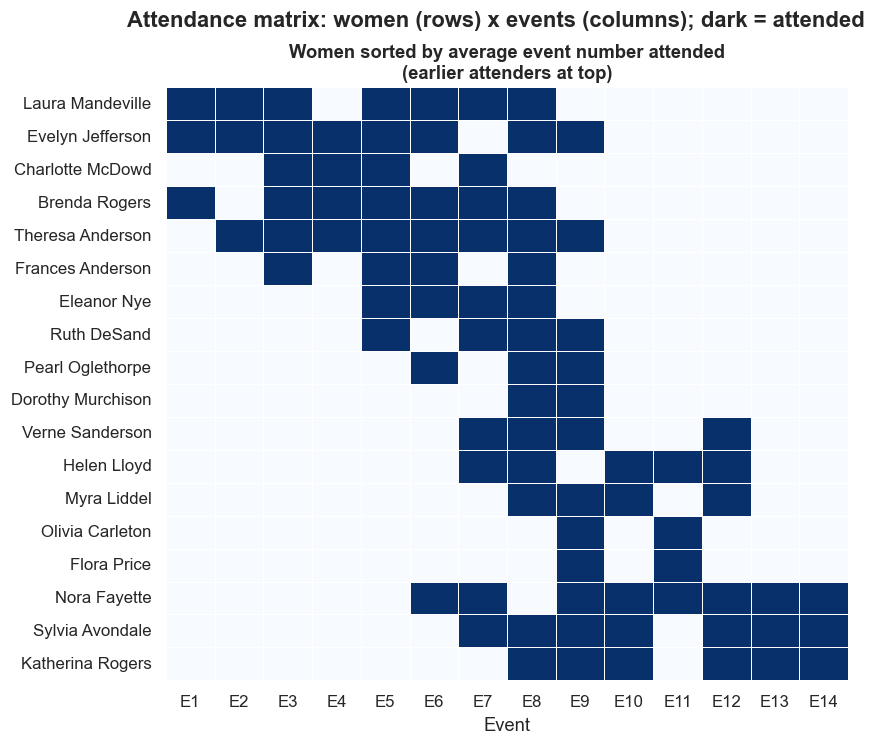

In [20]:
# Order women by community
col_order = sorted(clubs, key=lambda e: int(e[1:]))
# sort women by the average event number they attend (early -> late)
mean_event = A_df.apply(lambda r: np.mean([int(c[1:]) for c in col_order if r[c]]), axis=1)
row_order = mean_event.sort_values().index

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(A_df.loc[row_order, col_order], cmap="Blues", cbar=False,
            linewidths=.5, linecolor="white", ax=ax)
ax.set_title("Women sorted by average event number attended\n(earlier attenders at top)", weight="bold")
ax.set_xlabel("Event")
ax.set_ylabel("")
fig.suptitle("Attendance matrix: women (rows) x events (columns); dark = attended", weight="bold", y=0.98)
plt.show()

**Interpretation**

-   Women are ordered by the average event index they attend, so a clear diagonal band appears: top rows attend early events (E1–E6, E8), bottom rows attend late ones (E9–E14). Not a random cloud — the signature of overlapping subgroups.

-   E8 and E9 are almost solid (many women attend); E1, E2, E13, E14 have only three marks each.

-   The women at E1–E5 are different from those at E10–E14 (no overlap), while E6–E9 are mixed. The bottom rows (Nora Fayette, Sylvia Avondale, Katherina Rogers) span E6/E7→E14, linking mid-season to the end.

**Takeaway:** two groups with some overlap 

## 5. Degree Distributions: Who Is Active, Which Events Are Big?

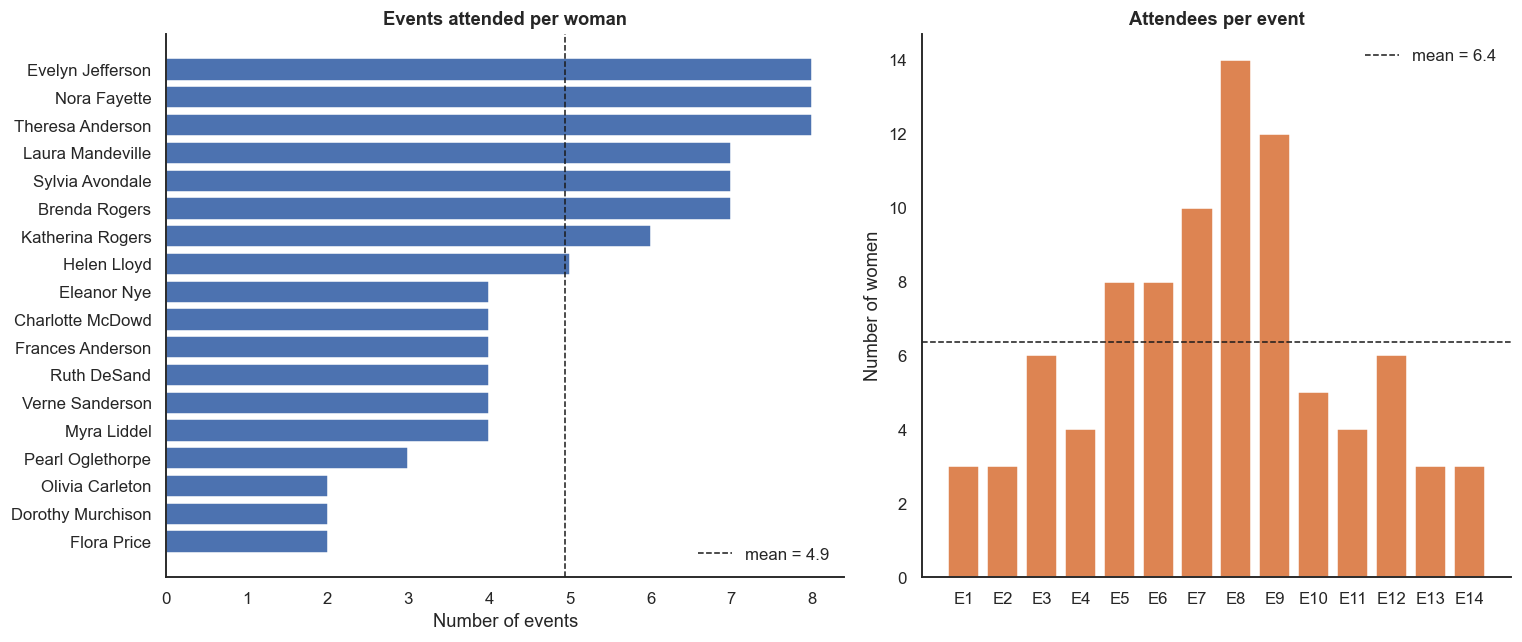

Largest events : {'E8': 14, 'E9': 12, 'E7': 10}
Smallest events: {'E1': 3, 'E2': 3, 'E13': 3, 'E14': 3}


In [6]:
women_deg = pd.Series(dict(G.degree(women))).sort_values()
event_deg = pd.Series(dict(G.degree(clubs))).reindex(col_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.15, 1]})
axes[0].barh(women_deg.index, women_deg.values, color=C_WOMEN)
axes[0].axvline(women_deg.mean(), color="k", ls="--", lw=1, label=f"mean = {women_deg.mean():.1f}")
axes[0].set_title("Events attended per woman", weight="bold"); axes[0].set_xlabel("Number of events")
axes[0].legend(frameon=False)

axes[1].bar(event_deg.index, event_deg.values, color=C_EVENT)
axes[1].axhline(event_deg.mean(), color="k", ls="--", lw=1, label=f"mean = {event_deg.mean():.1f}")
axes[1].set_title("Attendees per event", weight="bold"); axes[1].set_ylabel("Number of women")
axes[1].legend(frameon=False)
sns.despine()
plt.tight_layout(); plt.show()

print("Largest events :", event_deg.sort_values(ascending=False).head(3).to_dict())
print("Smallest events:", event_deg.sort_values().head(4).to_dict())

**Interpretation.**
- **Women's activity is uneven.** Three women (Evelyn Jefferson, Theresa Anderson, Nora Fayette) attend 8 events, which is more than half of all events, while three (Olivia Carleton, Flora Price, Dorothy Murchison) attend only 2. This is a core/periphery pattern.
- **Events are even more unequal.** E8 (14 attendees) and E9 (12) draw most of the group, i.e. roughly 3-4 times the size of the typical small event (3-4 guests). These are the "town-wide" occasions, while E1, E2, E13, E14 are small, intimate gatherings.
- This matters for the projections below: sharing a large event such as E8 is weak evidence of a close relationship (many people were there), whereas sharing several small events is strong evidence.

## 6. Women-to-Women Network (One-Mode Projection)

We now ask which women are connected through shared events. We create two versions of the projection:
- **unweighted:** an edge means "attended at least one event together";
- **weighted:** the edge weight is the *number* of events they attended together.

In [21]:
W  = bipartite.projected_graph(G, women)            # unweighted
Ww = bipartite.weighted_projected_graph(G, women)   # weight = shared events

print(f"Unweighted projection: {W.number_of_edges()} edges, density = {nx.density(W):.3f}")
weights_all = np.array([d["weight"] for _, _, d in Ww.edges(data=True)])
print(f"Weighted projection: weights range {weights_all.min()}-{weights_all.max()}, "
      f"mean {weights_all.mean():.2f}")

Unweighted projection: 139 edges, density = 0.908
Weighted projection: weights range 1-7, mean 2.32


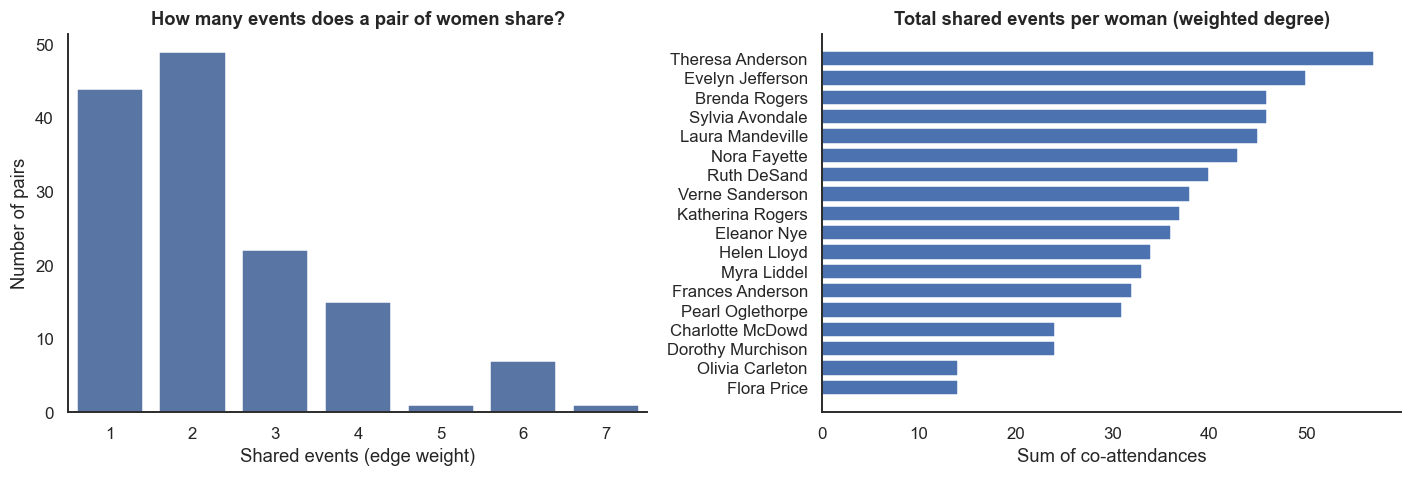

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x=weights_all, color=C_WOMEN, ax=axes[0])
axes[0].set_title("How many events does a pair of women share?", weight="bold")
axes[0].set_xlabel("Shared events (edge weight)"); axes[0].set_ylabel("Number of pairs")

order = strength.index
axes[1].barh(order[::-1], strength["total_shared_events"][::-1], color=C_WOMEN)
axes[1].set_title("Total shared events per woman (weighted degree)", weight="bold")
axes[1].set_xlabel("Sum of co-attendances")
sns.despine(); plt.tight_layout(); plt.show()

**Interpretation.**
- The unweighted projection has 139 of 153 possible edges, a density of **0.91**. That means *almost every woman shares at least one event with almost every other woman*, which is largely driven by the big events E7–E9. The unweighted graph therefore says very little.
- The weighted view is far more informative. Most pairs share only **1-2 events** (93 of the 139 connected pairs), while only 8 pairs share **6-7**. Those strong ties are where social closeness is most plausible.
- **Theresa Anderson (57), Evelyn Jefferson (50), Brenda Rogers (46) and Sylvia Avondale (46)** have the largest total co-attendance. **Olivia Carleton and Flora Price (14 each)** have the least.
- Conclusion: from here on we use the **weighted** projection.

### 6.1 Visualising the weighted women's network

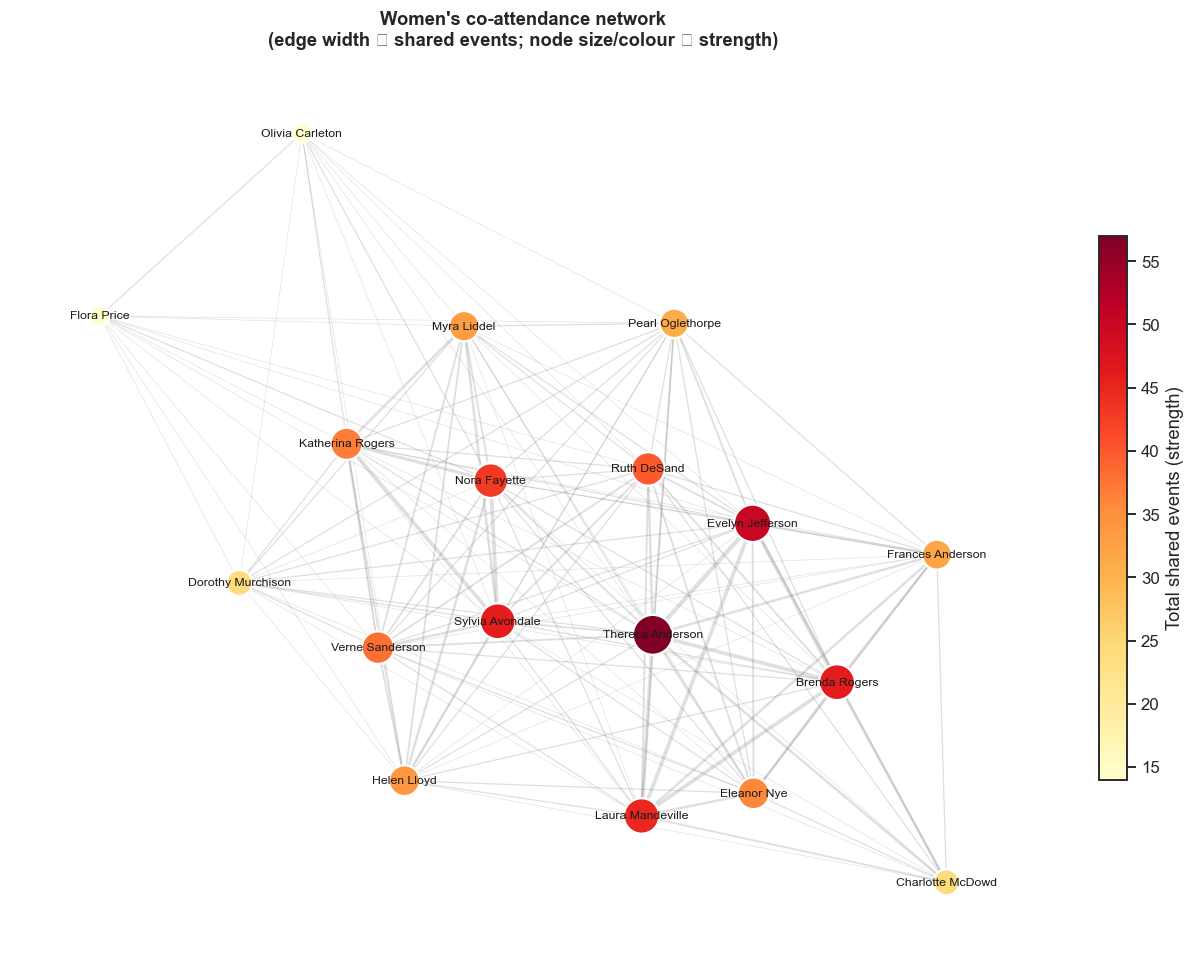

In [9]:
pos_w = nx.spring_layout(Ww, seed=648, weight="weight")
ew = np.array([Ww[u][v]["weight"] for u, v in Ww.edges()])
strength_s = pd.Series(dict(Ww.degree(weight="weight")))

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(Ww, pos_w, width=ew / 2.5, alpha=0.25, edge_color="gray", ax=ax)
nx.draw_networkx_nodes(Ww, pos_w, node_size=strength_s[list(Ww.nodes())] * 12,
                       node_color=strength_s[list(Ww.nodes())], cmap="YlOrRd",
                       edgecolors="white", linewidths=1.5, ax=ax)
nx.draw_networkx_labels(Ww, pos_w, font_size=8, ax=ax)
sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=plt.Normalize(strength_s.min(), strength_s.max()))
plt.colorbar(sm, ax=ax, shrink=0.6, label="Total shared events (strength)")
ax.set_title("Women's co-attendance network\n(edge width ∝ shared events; node size/colour ∝ strength)", weight="bold")
ax.axis("off"); plt.tight_layout(); plt.show()

**Interpretation.**
- The highly connected women (dark, large nodes: Theresa, Evelyn, Brenda, Sylvia, Laura, Nora) sit in the **centre** of the layout, and the lightly attached women (Olivia, Flora, Dorothy, Charlotte) are pushed to the **edge**. This is a classic core-periphery shape.

- The layout is *force-directed*: nodes with heavy ties are pulled together. Even though nearly every pair is connected, the thick edges concentrate in a lower-right cluster (Theresa, Evelyn, Brenda, Laura, Eleanor, Frances) and a left-hand cluster (Nora, Sylvia, Verne, Katherina, Helen). This hints at two subgroups; we test it formally with community detection.


## 7. Community Detection: Do the Women Form Groups?

A *community* is a set of nodes more densely tied to each other than to the rest. We use **modularity** (Q) as the quality score: Q close to 0 means a partition is no better than chance, and larger values mean clearer group structure. We try three algorithms to check that the result does not depend on one method.

In [24]:
def to_sets(comms):
    return sorted((set(c) for c in comms), key=lambda s: -len(s))

method = {
    "Greedy modularity": to_sets(greedy_modularity_communities(Ww, weight="weight"))
}
for name, comms in method.items():
    q = modularity(Ww, comms, weight="weight")
    print(f"\n{name}: {len(comms)} communities, Q = {q:.3f}")
    for i, c in enumerate(comms, 1):
        print(f"  C{i} ({len(c)}): {sorted(c)}")


Greedy modularity: 2 communities, Q = 0.152
  C1 (10): ['Dorothy Murchison', 'Flora Price', 'Helen Lloyd', 'Katherina Rogers', 'Myra Liddel', 'Nora Fayette', 'Olivia Carleton', 'Pearl Oglethorpe', 'Sylvia Avondale', 'Verne Sanderson']
  C2 (8): ['Brenda Rogers', 'Charlotte McDowd', 'Eleanor Nye', 'Evelyn Jefferson', 'Frances Anderson', 'Laura Mandeville', 'Ruth DeSand', 'Theresa Anderson']


**Interpretation.**
- Greedy modularity split into **two communities (10 and 8 women)**, with a modularity of about 0.15 on the full weighted projection. Q is modest in absolute terms because the projection is so dense, but it is clearly above zero.


### 7.1 Strengthening the signal: pruning weak ties

Since single co-attendances are mostly noise from large events, we drop edges with weight < 2 and re-run the detection. If the groups are real they should become *clearer*, not disappear.

In [25]:
threshold = 2
Wp = Ww.copy()
Wp.remove_edges_from([(u, v) for u, v, d in Ww.edges(data=True) if d["weight"] < threshold])

print(f"Edges: {Ww.number_of_edges()} -> {Wp.number_of_edges()} after removing weight < {threshold}")
print(f"Density: {nx.density(Ww):.2f} -> {nx.density(Wp):.2f}")

comms_greedy = to_sets(greedy_modularity_communities(Wp, weight="weight"))
Q_full = modularity(Ww, comms_greedy, weight="weight")
Q_pruned = modularity(Wp, comms_greedy, weight="weight")
print(f"\nCommunities found: {[len(c) for c in comms_greedy]}")
print(f"Modularity on full graph: {Q_full:.3f}   on pruned graph: {Q_pruned:.3f}")

community_map = {w: i for i, c in enumerate(comms_greedy) for w in c}

Edges: 139 -> 95 after removing weight < 2
Density: 0.91 -> 0.62

Communities found: [10, 8]
Modularity on full graph: 0.152   on pruned graph: 0.190


**Interpretation.** Pruning removes about 30% of the edges and lifts modularity from about 0.15 to about 0.19. The partition is unchanged (the same 10 + 8 split), so the structure is **robust**: it is not an artefact of weak, incidental overlaps. The groups were already present in the strong ties.

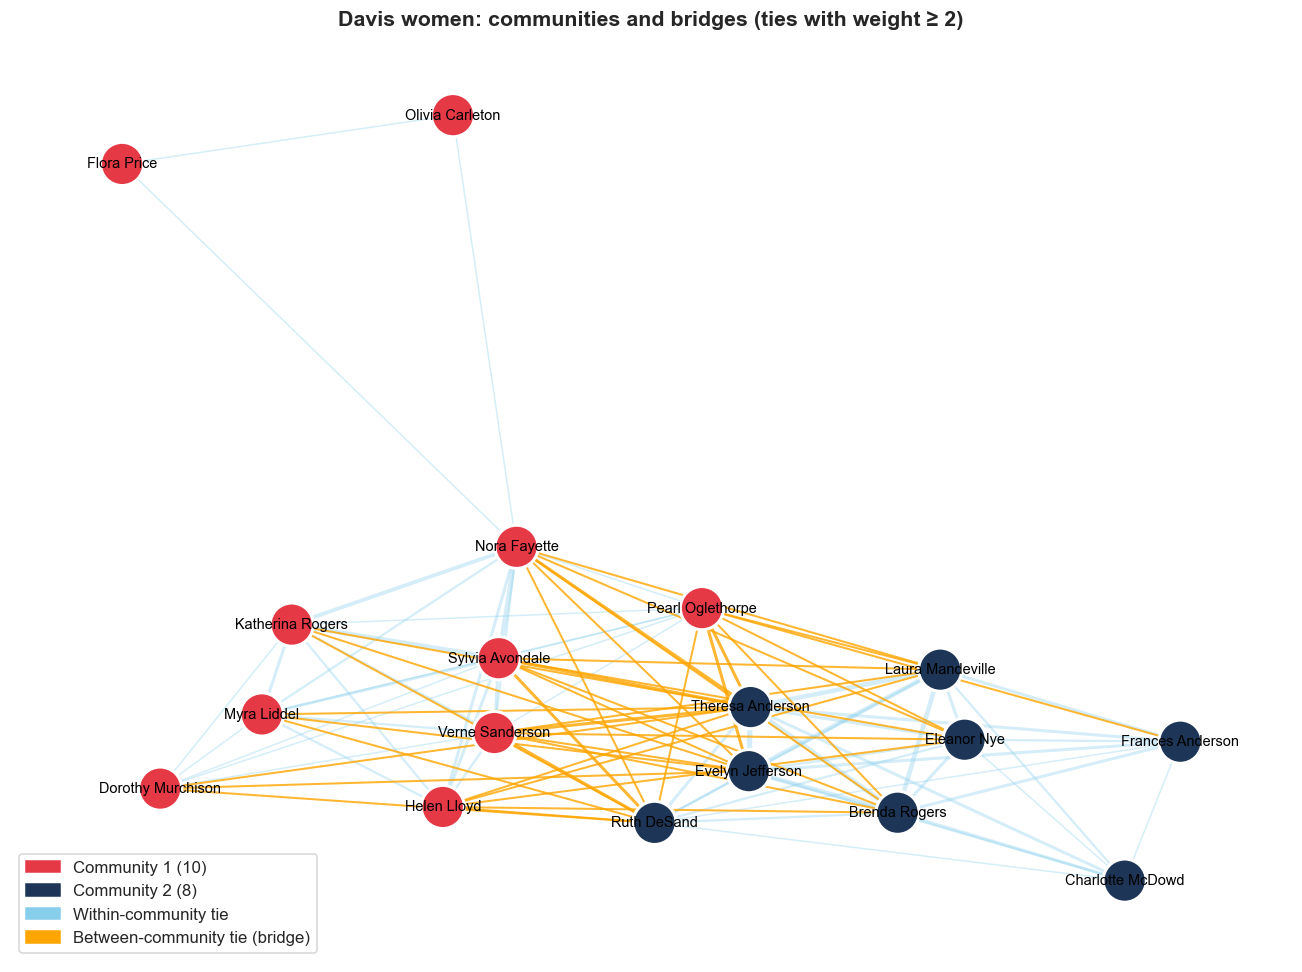

In [37]:
pos_c = nx.spring_layout(Wp, seed=648, weight="weight")
intra = [(u, v) for u, v in Wp.edges() if community_map[u] == community_map[v]]
inter = [(u, v) for u, v in Wp.edges() if community_map[u] != community_map[v]]

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(Wp, pos_c, edgelist=intra, width=[Wp[u][v]["weight"] / 2 for u, v in intra],
                       alpha=0.35, edge_color="skyblue", ax=ax)
nx.draw_networkx_edges(Wp, pos_c, edgelist=inter, width=[Wp[u][v]["weight"] / 1.5 for u, v in inter],
                       alpha=0.8, edge_color="orange", ax=ax)
nx.draw_networkx_nodes(Wp, pos_c, node_size=800, node_color=[PALETTE[community_map[w]] for w in Wp.nodes()],
                       edgecolors="white", linewidths=2, ax=ax)
nx.draw_networkx_labels(Wp, pos_c, font_size=9.5, font_color="black", ax=ax)
ax.legend(handles=[
    mpatches.Patch(color=PALETTE[0], label=f"Community 1 ({len(comms_greedy[0])})"),
    mpatches.Patch(color=PALETTE[1], label=f"Community 2 ({len(comms_greedy[1])})"),
    mpatches.Patch(color="skyblue", label="Within-community tie"),
    mpatches.Patch(color="orange", label="Between-community tie (bridge)")],
    loc="lower left")
ax.set_title("Davis women: communities and bridges (ties with weight ≥ 2)", fontsize=14, weight="bold")
ax.axis("off"); plt.tight_layout(); plt.show()

**Interpretation.**
- The two colours occupy largely separate regions of the layout, so the force-directed picture independently agrees with the algorithm.
- Orange **bridge ties** connect the two groups. There are 39 of them among the 95 remaining edges, so the groups are far from isolated: they overlap through shared events, mainly the large ones.
- The strongest bridges involve **Theresa Anderson, Ruth DeSand and Evelyn Jefferson** (community 2) tying to **Pearl Oglethorpe, Sylvia Avondale, Verne Sanderson and Nora Fayette** (community 1). These women are the social "brokers" between the two groups. The next table quantifies this.

,bridge_strength,community
Theresa Anderson,20,2
Ruth DeSand,18,2
Pearl Oglethorpe,16,1
Evelyn Jefferson,15,2
Verne Sanderson,14,1
Sylvia Avondale,14,1
Nora Fayette,13,1
Laura Mandeville,10,2
Helen Lloyd,10,1
Brenda Rogers,10,2


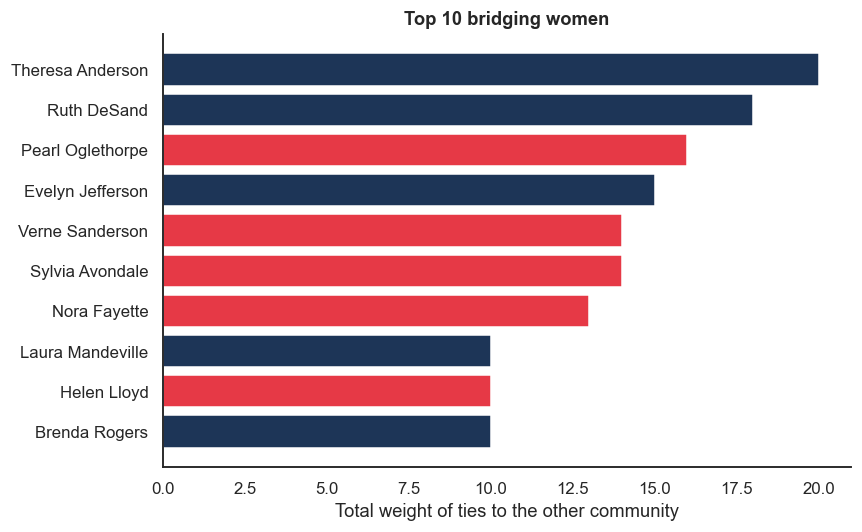

In [38]:
bridge = {}
for u, v in inter:
    w = Wp[u][v]["weight"]
    bridge[u] = bridge.get(u, 0) + w
    bridge[v] = bridge.get(v, 0) + w
bridge_df = (pd.DataFrame({"bridge_strength": pd.Series(bridge)})
               .assign(community=lambda d: d.index.map(lambda n: community_map[n] + 1))
               .sort_values("bridge_strength", ascending=False))
display(bridge_df.head(10))

fig, ax = plt.subplots(figsize=(8, 5))
top = bridge_df.head(10).iloc[::-1]
ax.barh(top.index, top["bridge_strength"], color=[PALETTE[c - 1] for c in top["community"]])
ax.set_xlabel("Total weight of ties to the other community")
ax.set_title("Top 10 bridging women", weight="bold"); 
sns.despine(); 
plt.tight_layout(); 
plt.show()

**Interpretation.** 
-   The women at the top of the list are the bridges, their attendance spans both groups, so they're the most likely paths for information or influence to travel between the two circles.

-   Being a bridge is not the same as being very active. **Ruth DeSand**, for example, only goes to 4 events **(E5, E7, E8, E9)**, yet she's the second-strongest bridge, because those few events sit right across the boundary between the two groups.

-   The peripheral women **(Olivia, Flora, Dorothy)** don't show up in the top 10, they stay inside one group rather than connecting the two.

### 7.2 Does the partition match the data? Assortativity and mixing

Assortativity by community: r = 0.179


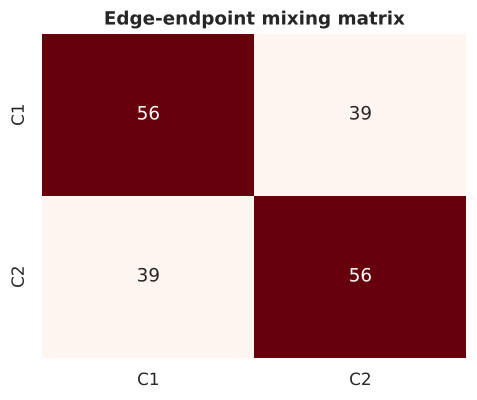

In [13]:
nx.set_node_attributes(Wp, community_map, "community")
r = nx.attribute_assortativity_coefficient(Wp, "community")
print(f"Assortativity by community: r = {r:.3f}")

k = len(comms_greedy)
M = np.zeros((k, k), dtype=int)
for u, v in Wp.edges():
    M[community_map[u], community_map[v]] += 1
    M[community_map[v], community_map[u]] += 1
mix = pd.DataFrame(M, index=[f"C{i+1}" for i in range(k)], columns=[f"C{i+1}" for i in range(k)])

plt.figure(figsize=(4.5, 3.8))
sns.heatmap(mix, annot=True, fmt="d", cmap="Reds", cbar=False)
plt.title("Edge-endpoint mixing matrix", weight="bold"); plt.tight_layout(); plt.show()

**Interpretation.** 
-   Assortativity measures how often ties stay inside a group, compared to what you'd get if ties were made at random. The scale runs from 0 (random) to 1 (perfectly segregated).

-   A positive value means people stick with their own group more than chance would predict: that's homophily, the tendency to associate with similar people.

-   The mixing matrix shows this visually: the diagonal = ties within the same group, the off-diagonal = ties across groups.

-   Here r ≈ 0.18, a small but positive value, so there's some grouping, but it's far from a clean split.

**Concretely:** of the 95 remaining ties, 56 stay within a community and 39 cross between them. So the diagonal wins, but the off-diagonal is nowhere near empty.

**Takeaway:** the two circles are distinct but overlapping not one big crowd, and not two separate ones either.

## 8. Strengthening the Women's View: Co-attendance Matrix by Community

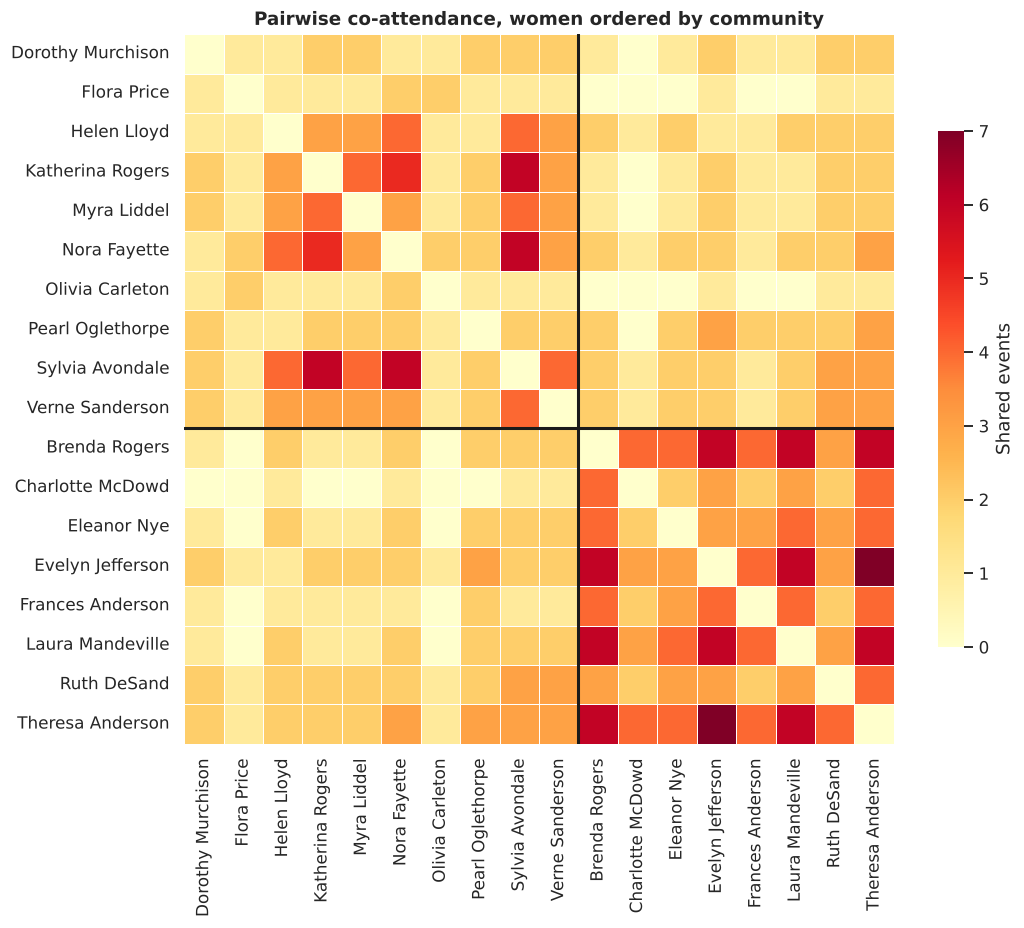

In [14]:
order_c = [w for c in comms_greedy for w in sorted(c)]
M_co = nx.to_pandas_adjacency(Ww, nodelist=order_c, weight="weight")

plt.figure(figsize=(10, 8.5))
sns.heatmap(M_co, cmap="YlOrRd", square=True, linewidths=.4, linecolor="white",
            cbar_kws={"label": "Shared events", "shrink": .7})
n1 = len(comms_greedy[0])
plt.axhline(n1, color="k", lw=2); plt.axvline(n1, color="k", lw=2)
plt.title("Pairwise co-attendance, women ordered by community", weight="bold")
plt.tight_layout(); plt.show()

**Interpretation.** 

-   With women grouped by community, the two diagonal blocks are visibly darker than the off-diagonal blocks, so women share more events with members of their own group. 

-   The highest values (6-7 shared events) all lie inside the blocks. The off-diagonal blocks are not empty, in line with the bridge ties found above.

-   This one picture summarises the whole women's network: **two cohesive groups with moderate overlap**.

## 9. Event-to-Event Network (the Other Projection)

Now we flip the projection and ask which events share guests. An edge's weight is the number of women who attended both events.

Event communities (Greedy Modularity):
  Cluster 1: ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8']
  Cluster 2: ['E9', 'E10', 'E11', 'E12', 'E13', 'E14']
Modularity Q = 0.172


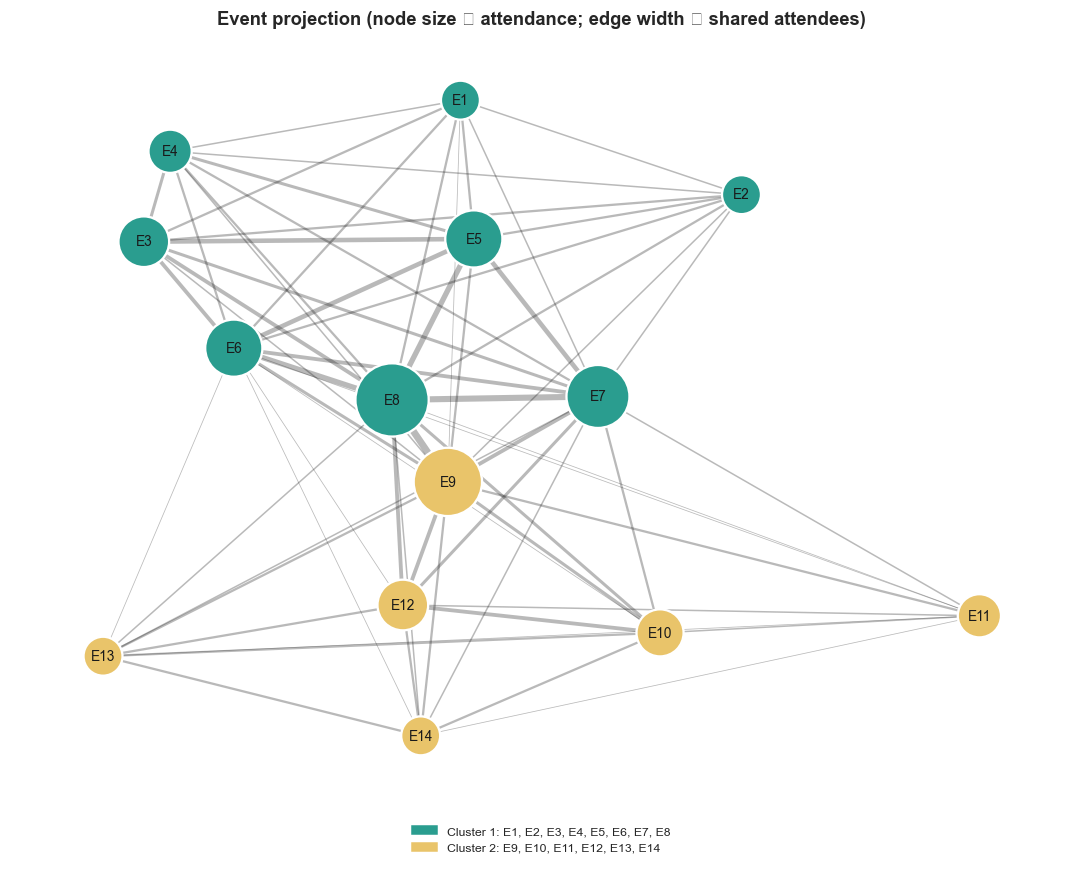

In [39]:
E = bipartite.weighted_projected_graph(G, clubs)
comms_e = to_sets(nx.community.greedy_modularity_communities(E, weight="weight"))
comm_e_map = {e: i for i, c in enumerate(comms_e) for e in c}
print("Event communities (Greedy Modularity):")
for i, c in enumerate(comms_e, 1):
    print(f"  Cluster {i}: {sorted(c, key=lambda e: int(e[1:]))}")
print(f"Modularity Q = {modularity(E, comms_e, weight='weight'):.3f}")

pos_e = nx.spring_layout(E, seed=42, weight="weight")
w_e = np.array([E[u][v]["weight"] for u, v in E.edges()])
size_e = [150 * G.degree(e) + 200 for e in E.nodes()]

fig, ax = plt.subplots(figsize=(10, 8))
nx.draw_networkx_edges(E, pos_e, width=w_e / 2, alpha=0.3, ax=ax)
nx.draw_networkx_nodes(E, pos_e, node_size=size_e, node_color=[["#2A9D8F", "#E9C46A"][comm_e_map[e]] for e in E.nodes()],
                       edgecolors="white", linewidths=1.5, ax=ax)
nx.draw_networkx_labels(E, pos_e, font_size=9, ax=ax)
ax.legend(handles=[mpatches.Patch(color="#2A9D8F", label=f"Cluster 1: {', '.join(sorted(comms_e[0], key=lambda e: int(e[1:])))}"),
                   mpatches.Patch(color="#E9C46A", label=f"Cluster 2: {', '.join(sorted(comms_e[1], key=lambda e: int(e[1:])))}")],
          loc="lower center", bbox_to_anchor=(0.5, -0.08), frameon=False, fontsize=8)
ax.set_title("Event projection (node size ∝ attendance; edge width ∝ shared attendees)", weight="bold")
ax.axis("off"); plt.tight_layout(); plt.show()

**Interpretation.**
- Events split into two clusters: **E1-E8** and **E9-E14**. If the event numbers follow time (as they do in the source), this suggests an "earlier" and a "later" social season, with different crowds.
- **E8 and E9** have the strongest tie (9 shared attendees) and the largest nodes. They sit between the clusters and hold the graph together, serving as the main events where the two groups come into contact.

- **E1-E5** are small to medium events, closely tied to each other, while **E10-E14** form a separate tight cluster.


### 9.1 Event similarity (Jaccard index)

Raw shared counts favour large events. The **Jaccard index** (shared guests ÷ combined guests) corrects for size, so it identifies events that draw the *same kind of crowd* regardless of size.

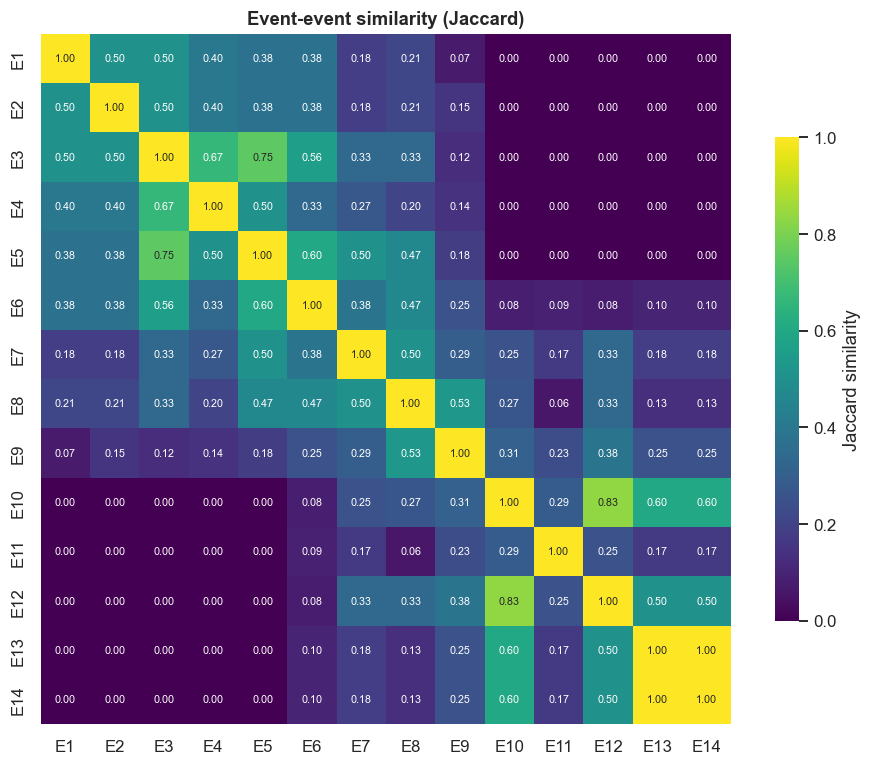

Most similar event pairs:
  E13 ~ E14: 1.00
  E10 ~ E12: 0.83
  E3 ~ E5: 0.75
  E3 ~ E4: 0.67
  E5 ~ E6: 0.60


In [40]:
guests = {e: set(G[e]) for e in clubs}
J = pd.DataFrame([[len(guests[a] & guests[b]) / len(guests[a] | guests[b]) for b in col_order]
                  for a in col_order], index=col_order, columns=col_order)

plt.figure(figsize=(8.5, 7))
sns.heatmap(J, cmap="viridis", annot=True, fmt=".2f", annot_kws={"size": 7}, square=True,
            cbar_kws={"label": "Jaccard similarity", "shrink": .7})
plt.title("Event-event similarity (Jaccard)", weight="bold"); plt.tight_layout(); plt.show()

pairs = sorted(((a, b, J.loc[a, b]) for a, b in combinations(col_order, 2)), key=lambda x: -x[2])
print("Most similar event pairs:")
for a, b, j in pairs[:5]:
    print(f"  {a} ~ {b}: {j:.2f}")

**Interpretation.**
- The matrix has a clear **block structure**: a block for E1-E7 and another for E10-E14, with E8 and E9 lying between them.

- **E13 and E14 are perfectly identical (Jaccard = 1.0)**: exactly the same three women attended both. 

-   Likewise **E10 and E12** (0.83) and **E3 and E5** (0.75) draw very similar crowds. These pairs are functionally interchangeable events.

- E8 and E9 together have only a moderate Jaccard similarity (about 0.5) even though they share the most guests, which confirms that large events overlap mostly by volume, not by identical audience.

- Practically, a sociologist would treat these near-duplicate events as repeated gatherings of one friendship circle.

## 10. Linking the Two Views: Which Group Attends Which Event?

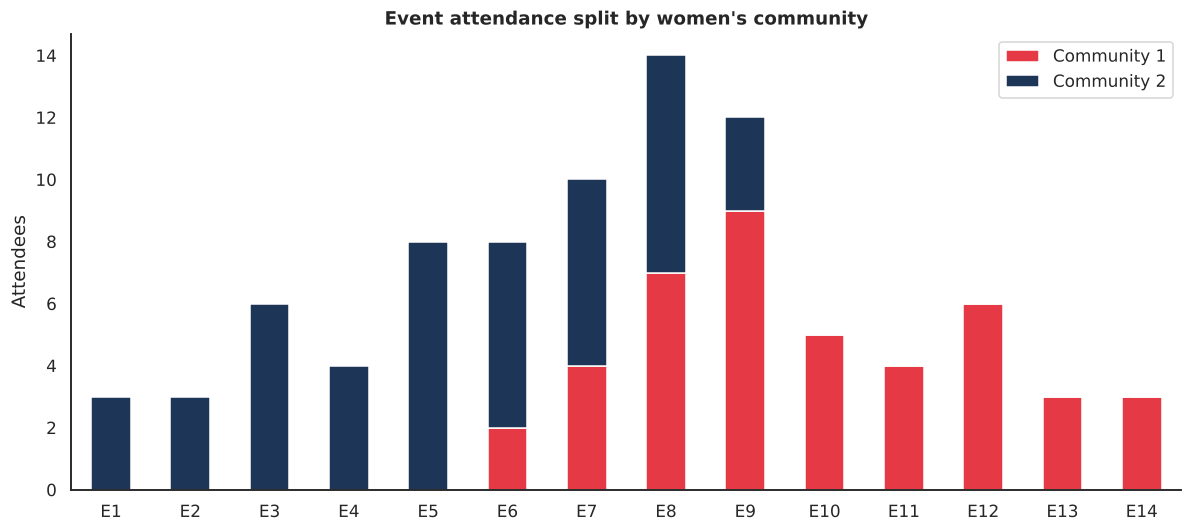

event,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,E11,E12,E13,E14
Community 1,0,0,0,0,0,2,4,7,9,5,4,6,3,3
Community 2,3,3,6,4,8,6,6,7,3,0,0,0,0,0


In [17]:
rows = []
for e in col_order:
    rows.append({"event": e, **{f"Community {i+1}": sum(G.has_edge(w, e) for w in c)
                                for i, c in enumerate(comms_greedy)}})
ev_df = pd.DataFrame(rows).set_index("event")

# Which community label is the 'early events' group? Plot in event order.
ax = ev_df.plot(kind="bar", stacked=True, figsize=(11, 5), color=PALETTE, edgecolor="white")
ax.set_ylabel("Attendees"); ax.set_xlabel("")
ax.set_title("Event attendance split by women's community", weight="bold")
plt.xticks(rotation=0); sns.despine(); plt.tight_layout(); plt.show()
ev_df.T

**Interpretation.**
- This is the key result that ties both projections together. Each of the events **E1-E5** is attended by women of **one community only**, and each of **E10-E14** by the **other community only**. 

-   The women of community 2 (the group containing Evelyn, Theresa, Brenda etc., navy) attend E1-E5, while community 1 (Nora, Sylvia, Pearl etc., red) attends E10-E14.

- **E6-E9 are mixed.** E8 draws 7 women from each group, and E9 draws 3 from community 2 and 9 from community 1. These are the shared social events, and they are where the cross-group bridge ties came from.

- Thus the event clusters (E1-E8 vs E9-E14) and the women's communities are two views of the *same* structure: **groups of women are defined by the events they attend, and events are defined by the women who attend them**. That is the duality of a two-mode network.

## 11. Centrality: Who Matters Most?

,strength (weighted degree),betweenness (bipartite graph),eigenvector (weighted),community
Theresa Anderson,57.0,0.084,0.354,2
Evelyn Jefferson,50.0,0.092,0.319,2
Brenda Rogers,46.0,0.047,0.304,2
Laura Mandeville,45.0,0.049,0.300,2
Sylvia Avondale,46.0,0.069,0.273,1
Nora Fayette,43.0,0.109,0.253,1
Ruth DeSand,40.0,0.016,0.249,2
Eleanor Nye,36.0,0.009,0.239,2
Verne Sanderson,38.0,0.015,0.231,1
Katherina Rogers,37.0,0.045,0.222,1


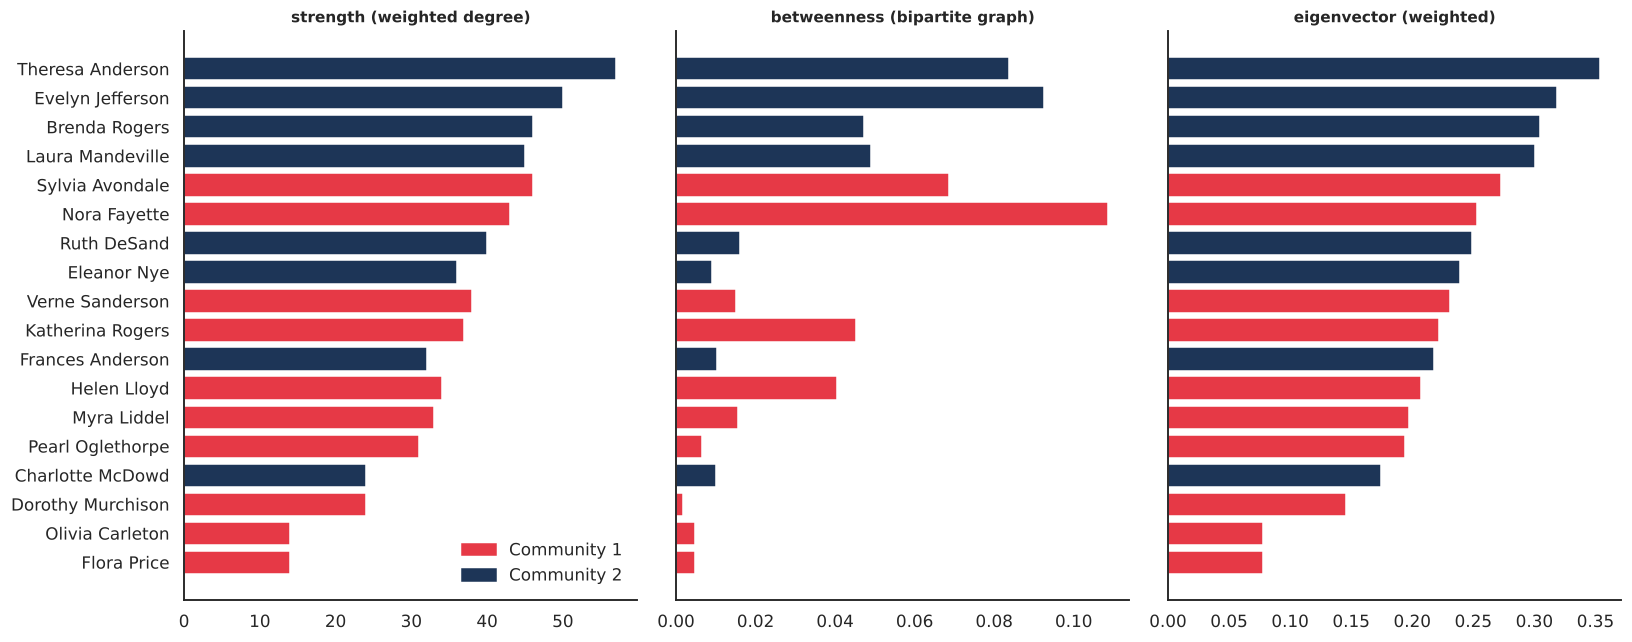

In [18]:
cent = pd.DataFrame({
    "strength (weighted degree)": pd.Series(dict(Ww.degree(weight="weight"))),
    "betweenness (bipartite graph)": pd.Series(nx.betweenness_centrality(G)),
    "eigenvector (weighted)": pd.Series(nx.eigenvector_centrality(Ww, weight="weight", max_iter=1000)),
}).loc[women]
cent["community"] = [community_map[w] + 1 for w in cent.index]

# Betweenness in the *projection* is uninformative (nearly complete graph), so we
# use betweenness in the original bipartite graph instead.
display(cent.sort_values("eigenvector (weighted)", ascending=False).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
order = cent.sort_values("eigenvector (weighted)").index
for ax, col in zip(axes, cent.columns[:3]):
    ax.barh(order, cent.loc[order, col], color=[PALETTE[c - 1] for c in cent.loc[order, "community"]])
    ax.set_title(col, weight="bold", fontsize=10)
axes[0].legend(handles=[mpatches.Patch(color=PALETTE[0], label="Community 1"),
                        mpatches.Patch(color=PALETTE[1], label="Community 2")], frameon=False, loc="lower right")
sns.despine(); plt.tight_layout(); plt.show()

**Interpretation.**
- **Theresa Anderson, Evelyn Jefferson, Brenda Rogers and Laura Mandeville** score highest on strength and eigenvector centrality: they attend many events *with other well-connected women*. In the 2-group split these are all in the same group, so that group has the most prominent "leaders".

- **Nora Fayette** stands out on **betweenness** (computed on the original two-mode graph): she is the highest-ranked woman, ahead of Evelyn and Theresa. Her attendance links otherwise separate sets of events, making her the most important *broker* even though her raw degree is not the highest.

- **Sylvia Avondale** is the most central woman in the *other* group on strength and eigenvector scores.

- **Olivia, Flora and Dorothy** are low on all three measures: peripheral in every sense.


## 12. Summary and Conclusions

**What we found about the women**
- The 18 women form **two overlapping social circles** (10 and 8 members). The algorithm broadly agree, and the split survives removing weak ties (modularity rises from ≈0.15 to ≈0.19), so it is robust.

- The unweighted projection is 91% complete and tells us almost nothing. **Weighting ties by the number of shared events is essential.**

- A **core** (Theresa Anderson, Evelyn Jefferson, Brenda Rogers, Laura Mandeville, Sylvia Avondale, Nora Fayette) attends the most events, while a **periphery** (Olivia Carleton, Flora Price, Dorothy Murchison) attends only two.

- A small set of women **bridge** the two circles: **Theresa Anderson, Ruth DeSand and Pearl Oglethorpe** have the strongest cross-group ties, and **Nora Fayette** has the highest betweenness in the original two-mode graph.

**What we found about the events**

- Events cluster into an **E1-E8** group and an **E9-E14** group. Several pairs are near-duplicates in audience (E13/E14 identical; E10/E12 and E3/E5 very similar).

- **E8 and E9** are the largest events and the main **meeting points**: they host women from both circles and carry most cross-group ties.

- Events E1-E5 and E10-E14 are each attended by a *single* group, so they act as the "private" gatherings of each circle.

**Linking both views.** Women's groups and event clusters mirror each other: each circle has its own set of exclusive events, and the circles meet only at a few large shared events. This is the *duality* at the heart of two-mode network analysis.


---
